# How To Map Ocean Plastic By Country: Staggering Results With Python

*Visualizing where river plastic enters the ocean with the Our World in Data country dataset*

**Data:** plastic-entering-ocean.csv, https://ourworldindata.org/grapher/plastic-entering-ocean.csv, data to 2019; plastic-entering-ocean-per-capita.csv, https://ourworldindata.org/grapher/plastic-entering-ocean.csv?measure=per_capita, data to 2019

**Article:** (link added when the article is published)

Run the cells in order. Dataset files are in the same folder as this notebook.

In [1]:
import plotly.io as pio
pio.renderers.default = "notebook_connected+png"  # interactive in Jupyter, image on GitHub

### The Dataset

The two datasets used here are both downloadable directly from Our World in Data:

In [2]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

df_abs = pd.read_csv("plastic-entering-ocean.csv")
df_cap = pd.read_csv("plastic-entering-ocean-per-capita.csv")

print(df_abs.columns.tolist())
print(df_abs.head())

['Entity', 'Code', 'Year', 'Plastic pollution entering the ocean through rivers']
                Entity Code  Year  \
0              Albania  ALB  2019   
1              Algeria  DZA  2019   
2               Angola  AGO  2019   
3  Antigua and Barbuda  ATG  2019   
4            Argentina  ARG  2019   

   Plastic pollution entering the ocean through rivers  
0                                               1565    
1                                               5774    
2                                                860    
3                                                  2    
4                                               4137    


### Chart 1: Who Sends the Most Per Person?

The first question is about burden: which countries send the most ocean plastic per person?

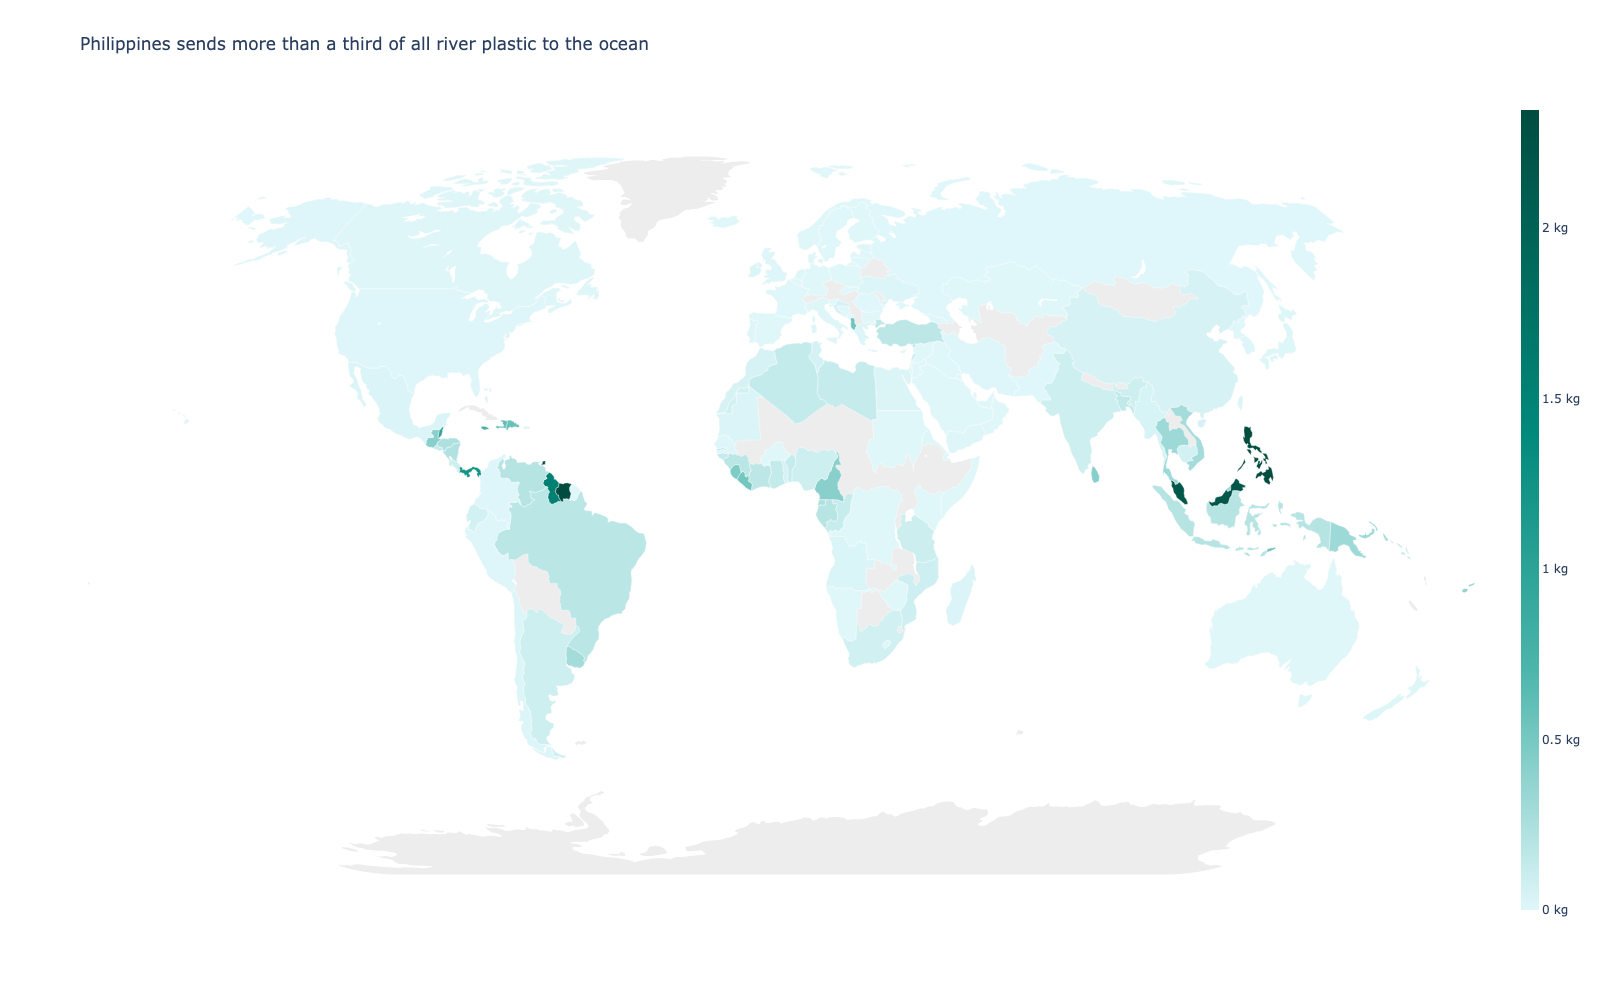

In [3]:
col_cap = "Plastic pollution entering the ocean through rivers, per person"

teal_scale = [[0, "#E0F7FA"], [0.3, "#4DB6AC"], [0.6, "#00897B"], [1.0, "#004D40"]]

fig = go.Figure(go.Choropleth(
    locations=df_cap["Code"],
    z=df_cap[col_cap],
    colorscale=teal_scale,
    zmin=0,
    zmax=df_cap[col_cap].quantile(0.98),
    marker_line_color="white",
    marker_line_width=0.4,
    colorbar=dict(ticksuffix=" kg", thickness=18),
))
fig.update_geos(
    showframe=False,
    showcoastlines=False,
    projection_type="natural earth",
    showland=True,
    landcolor="#EDEDED",
)
fig.update_layout(
    title="Philippines sends more than a third of all river plastic to the ocean",
    width=1600,
    height=1000,
)
fig.show()

### Chart 2: Where Does the Volume Actually Come From?

Per capita tells you about burden per person. But if you want to know where the ocean plastic actually comes from, you need absolute volume.

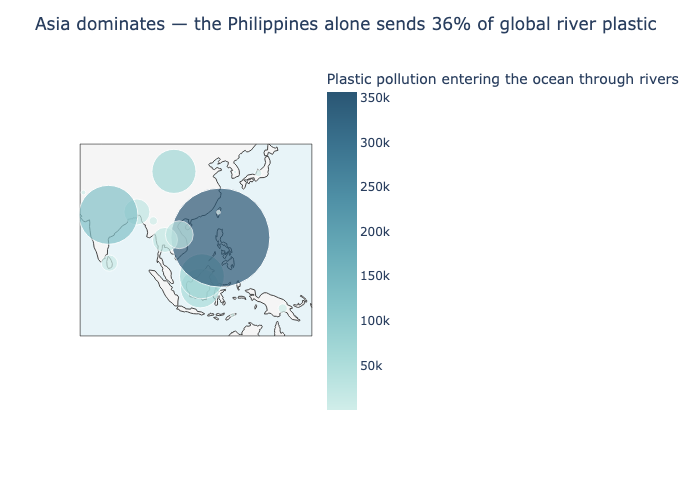

In [4]:
col_abs = "Plastic pollution entering the ocean through rivers"
df_bubble = df_abs[df_abs[col_abs] >= 100].copy()

fig = px.scatter_geo(
    df_bubble,
    locations="Code",
    size=col_abs,
    color=col_abs,
    hover_name="Entity",
    color_continuous_scale="Teal",
    size_max=70,
    projection="natural earth",
)
fig.update_geos(
    lonaxis_range=[70, 155],
    lataxis_range=[-15, 45],
    showland=True,
    landcolor="#F5F5F5",
    showocean=True,
    oceancolor="#E8F4F8",
)
fig.update_layout(
    title="Asia dominates — the Philippines alone sends 36% of global river plastic",
)
fig.show()

### Chart 3: The Top 15, Head to Head

Let's look at the full ranking. This horizontal bar chart shows the top 15 countries sorted by absolute volume:

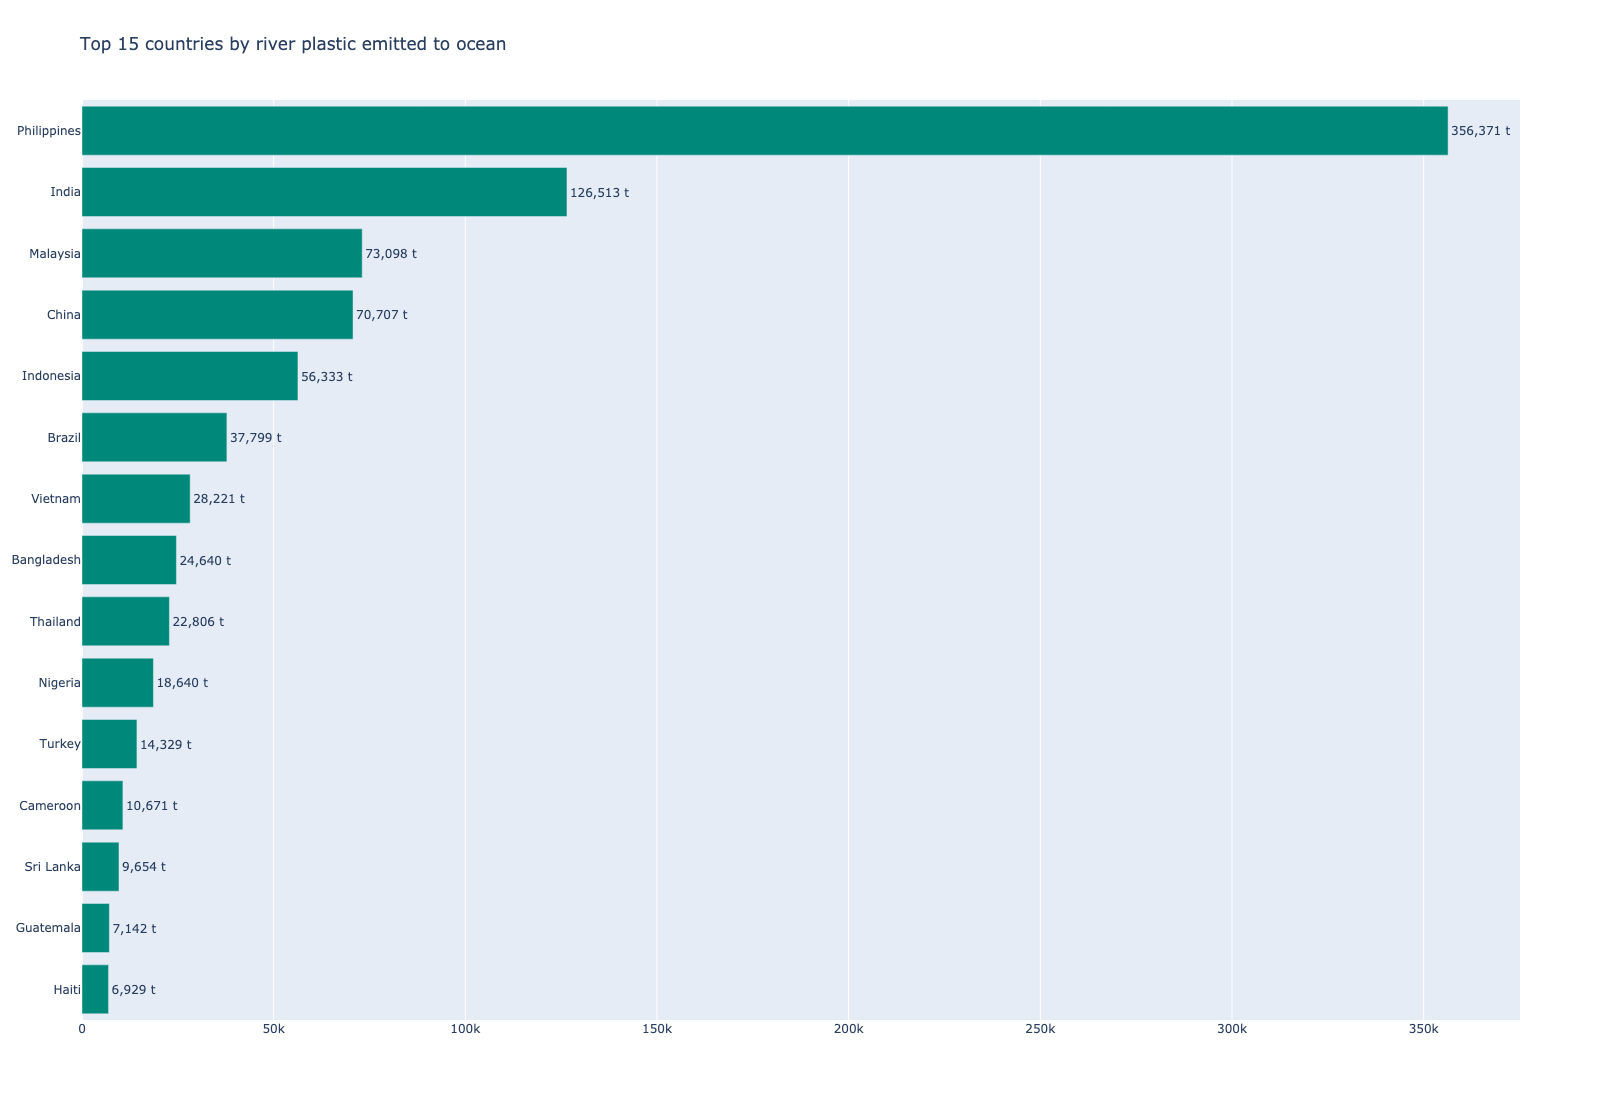

In [5]:
top15 = (
    df_abs[df_abs["Code"].notna()]
    .sort_values(col_abs, ascending=False)
    .head(15)
    .sort_values(col_abs, ascending=True)
)

fig = go.Figure(go.Bar(
    x=top15[col_abs],
    y=top15["Entity"],
    orientation="h",
    marker_color="#00897B",
    text=[f"{v:,.0f} t" for v in top15[col_abs]],
    textposition="outside",
))
fig.update_layout(
    title="Top 15 countries by river plastic emitted to ocean",
    width=1600,
    height=1100,
)
fig.show()